In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif' ] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus' ] = False

np.random.seed(42)
n_samples = 100
areas_m2 = np.random.uniform(90, 150, n_samples)
areas = areas_m2 / 100
prices = 250 * areas + 30 + np.random.randn(n_samples) * 15

print(f"房屋数量:{len(areas)}套")
print(f"面积范围:{areas_m2.min():.1f} - {areas_m2.max():.1f} 平米({areas.min():.2f} - {areas.max():.2f} 百平米)")
print(f"价格范围:{prices.min() :.1f}-{prices.max() :.1f} 万")
print(f"真实规律:房价=2.5 X 面积(平米) + 30")

#使用学习率更新参数

房屋数量:100套
面积范围:90.3 - 149.2 平米(0.90 - 1.49 百平米)
价格范围:248.0-414.8 万
真实规律:房价=2.5 X 面积(平米) + 30


In [3]:
def gradient_descent(X, y, lr=0.1, epochs=200):
    # 初始化参数
    w, b = 0.0, 0.0
    n = len(X)
    
    # 初始化历史记录,使用记录初始参数和损失
    history = {'w': [w], 'b': [b], 'loss': [np.mean((w*X + b - y) ** 2)]}
    
    # 进行迭代训练,更新参数
    for epoch in range(epochs):
        # 计算当前预测值
        y_pred = w * X + b
        
        # 计算参数 w 梯度
        dw =(2/n) * np.sum((y_pred - y) *X)
        # 计算参数 b 梯度
        db = (2/n) * np.sum(y_pred - y)
        
        # 使用学习率更新参数
        w -= lr * dw
        b -= lr * db
        
        # 记录参数和损失
        history['w'].append(w)
        history['b'].append(b)
        history['loss'].append(np.mean((y_pred - y)**2))
        
        # 每隔 1% 训练轮数,打印一次进度
        if epoch % (epochs/100) == 0:
            print(f"迭代{epoch:3d}: w={w:.2f}, b={b:.2f}, loss={history['loss'][-1]:.2f}")
    
    return history

history = gradient_descent(areas, prices, lr=0.01, epochs=100000)
print(f"\n最终结果: 房价 = {history['w'][-1]/100:.3f} x 面积(平米) + {history['b'][-1]:.2f}")

迭代  0: w=7.85, b=6.51, loss=107933.06
迭代1000: w=179.58, b=114.15, loss=291.90
迭代2000: w=193.12, b=97.93, loss=246.98
迭代3000: w=203.55, b=85.43, loss=220.33
迭代4000: w=211.59, b=75.81, loss=204.53
迭代5000: w=217.77, b=68.40, loss=195.15
迭代6000: w=222.54, b=62.70, loss=189.59
迭代7000: w=226.21, b=58.30, loss=186.29
迭代8000: w=229.04, b=54.91, loss=184.33
迭代9000: w=231.21, b=52.31, loss=183.17
迭代10000: w=232.89, b=50.30, loss=182.49
迭代11000: w=234.18, b=48.75, loss=182.08
迭代12000: w=235.17, b=47.56, loss=181.83
迭代13000: w=235.94, b=46.65, loss=181.69
迭代14000: w=236.53, b=45.94, loss=181.61
迭代15000: w=236.98, b=45.39, loss=181.56
迭代16000: w=237.33, b=44.98, loss=181.53
迭代17000: w=237.60, b=44.65, loss=181.51
迭代18000: w=237.81, b=44.40, loss=181.50
迭代19000: w=237.97, b=44.21, loss=181.49
迭代20000: w=238.09, b=44.07, loss=181.49
迭代21000: w=238.19, b=43.95, loss=181.48
迭代22000: w=238.26, b=43.86, loss=181.48
迭代23000: w=238.32, b=43.80, loss=181.48
迭代24000: w=238.36, b=43.75, loss=181.48
迭代25000: w

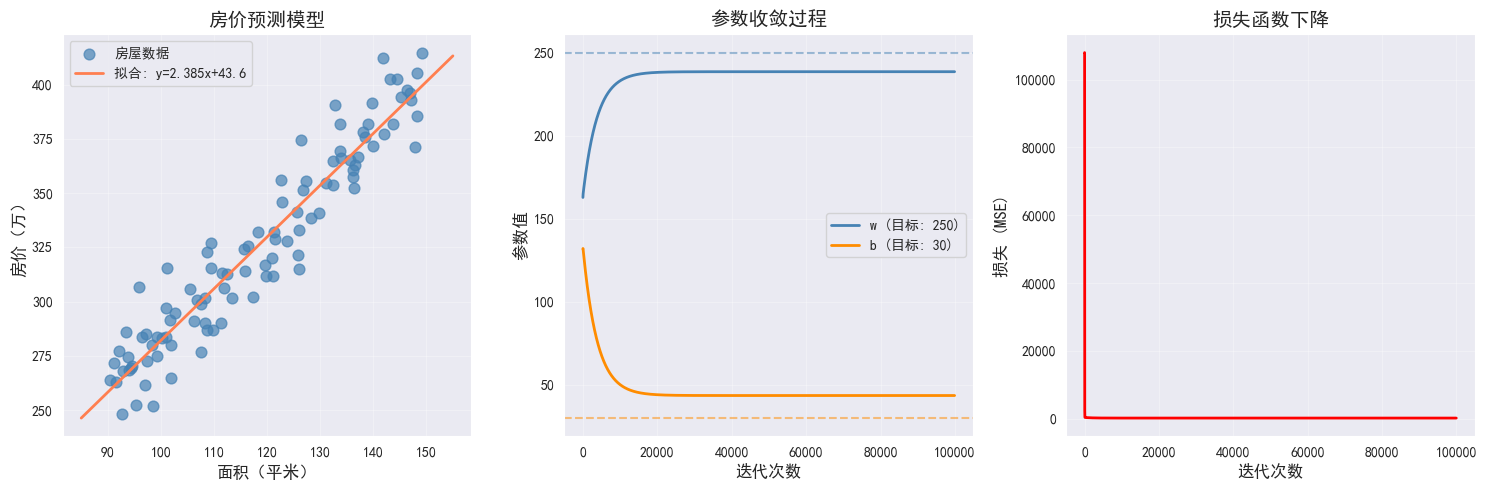

In [4]:
# ================= 可视化 =================
# 创建 1 行 3 列的子图布局
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# ------------ 图1：绘制房屋数据散点图与拟合曲线 ------------
# 绘制房屋数据散点图
axes[0].scatter(areas_m2, prices, c='steelblue', s=60, alpha=0.7, label='房屋数据')

# 绘制拟合曲线
x_line = np.linspace(85, 155, 100) # 在 (85, 155) 区间，生成 100 个等间距的点
# 注意：训练时X是百平米(除以了100)，所以计算预测线时 w 需要除以 100
y_line = (history['w'][-1]/100) * x_line + history['b'][-1] 
axes[0].plot(x_line, y_line, 'coral', lw=2, 
             label=f'拟合: y={history["w"][-1]/100:.3f}x+{history["b"][-1]:.1f}')

axes[0].set_xlabel('面积（平米）', fontsize=12)
axes[0].set_ylabel('房价（万）', fontsize=12)
axes[0].set_title('房价预测模型', fontsize=14)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# ------------ 图2：绘制参数收敛过程 ------------
# 跳过前 100 个迭代，避免初始值对收敛过程演示的干扰
skip = 100

# 绘制 w 目标值水平线 (真实值 w=250)
axes[1].axhline(250, color='steelblue', ls='--', alpha=0.5)
# 绘制 w 收敛过程
axes[1].plot(history['w'][skip:], 'steelblue', lw=2, label='w (目标: 250)')

# 绘制 b 目标值水平线 (真实值 b=30)
axes[1].axhline(30, color='darkorange', ls='--', alpha=0.5)
# 绘制 b 收敛过程
axes[1].plot(history['b'][skip:], 'darkorange', lw=2, label='b (目标: 30)')

axes[1].set_xlabel('迭代次数', fontsize=12)
axes[1].set_ylabel('参数值', fontsize=12)
axes[1].set_title('参数收敛过程', fontsize=14)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

# ------------ 图3：绘制损失函数下降 ------------
# 绘制损失曲线 (也可以跳过前100个点，但截图里似乎没有跳过，我们直接画)
axes[2].plot(history['loss'], 'red', lw=2)

axes[2].set_xlabel('迭代次数', fontsize=12)
axes[2].set_ylabel('损失 (MSE)', fontsize=12)
axes[2].set_title('损失函数下降', fontsize=14)
axes[2].grid(True, alpha=0.3)

# 调整布局并显示
plt.tight_layout()
plt.show()

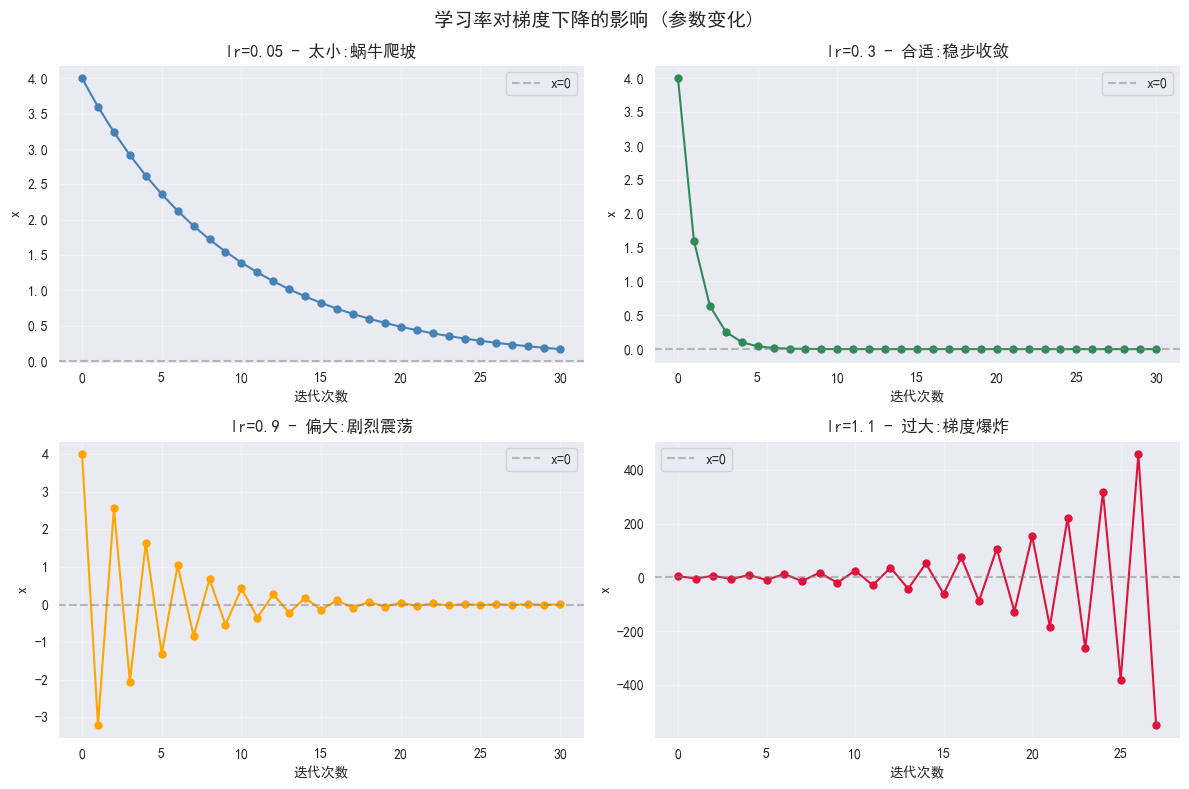

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 修复字体设置的间距问题
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ========= 核心逻辑 ==========
def gradient_descent(start_x, lr, n_steps=30):
    """在 f(x) = x² 上做梯度下降, 返回每步的 x 值"""
    trajectory = [start_x]
    x = start_x
    for _ in range(n_steps):
        grad = 2 * x            # f'(x) = 2x
        x = x - lr * grad       # 参数更新
        trajectory.append(x)
        if abs(x) > 500:        # 已经爆炸,提前停
            break
    return trajectory

# ============ 四种学习率对比 ==================
# 修复缩进：移到函数外面
x0 = 4.0
configs = [
    (0.05, '太小:蜗牛爬坡', 'steelblue'),
    (0.3,  '合适:稳步收敛', 'seagreen'),
    (0.9,  '偏大:剧烈震荡', 'orange'),
    (1.1,  '过大:梯度爆炸', 'crimson'),
]

# ----图1:参数值随迭代变化------------
# 修复整体画图代码的缩进
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (lr, title, color) in zip(axes.flatten(), configs):
    traj = gradient_descent(x0, lr)
    ax.plot(range(len(traj)), traj, 'o-', color=color, markersize=5)
    ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5, label='x=0')
    ax.set_title(f'lr={lr} - {title}', fontsize=12)
    ax.set_xlabel('迭代次数')
    ax.set_ylabel('x')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('学习率对梯度下降的影响 (参数变化)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\27813\AppData\Local\Temp\ipykernel_29668\3472534768.py:67: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from current font.
  plt.tight_layout()
D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


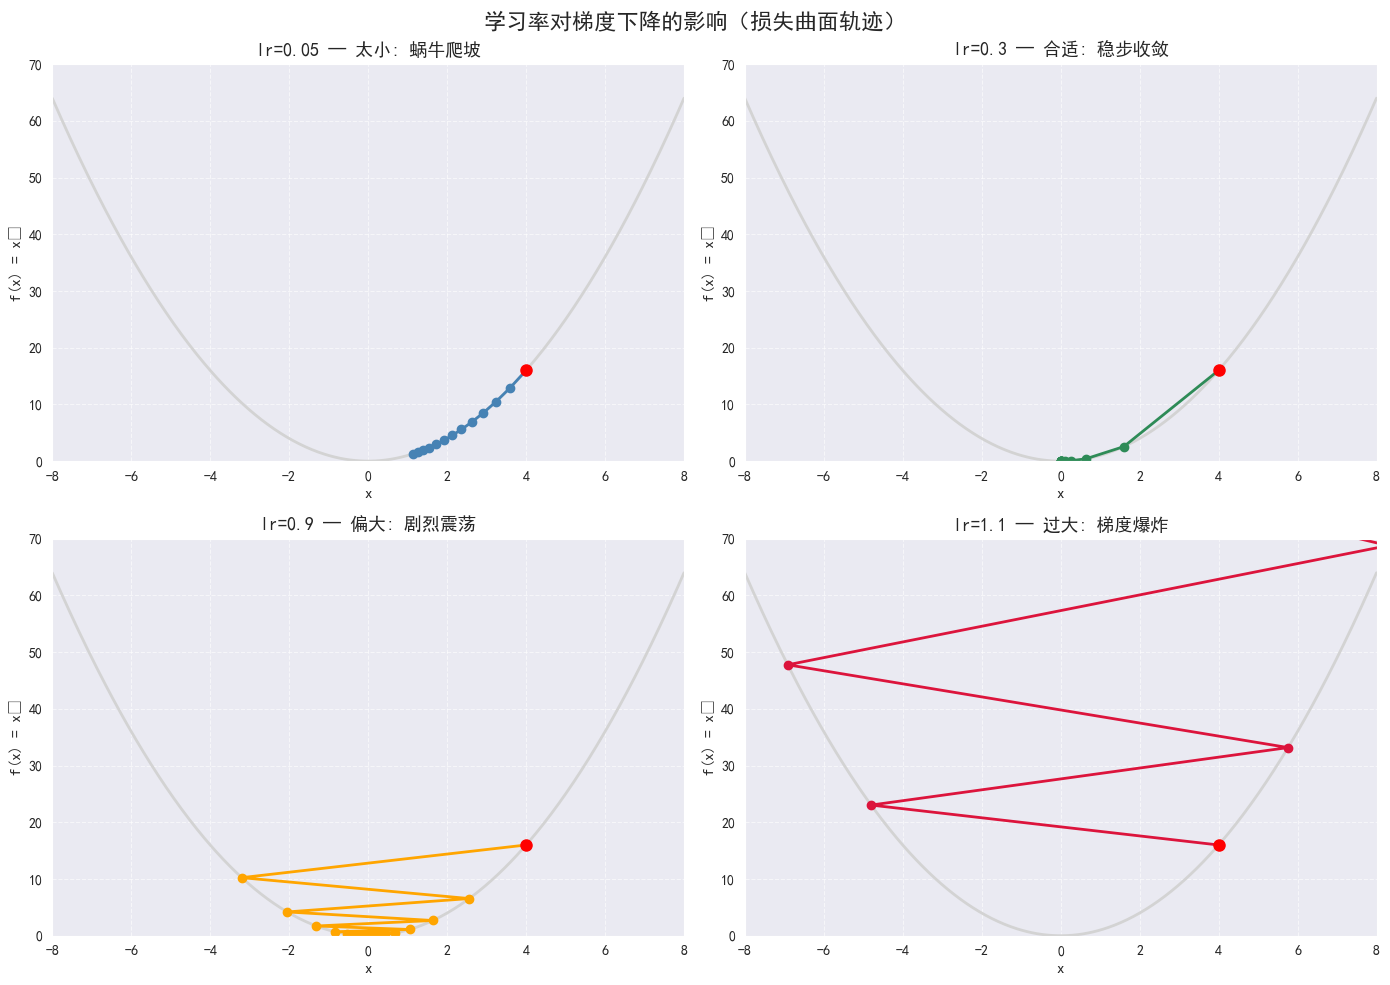

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ========= 核心逻辑 ==========
def gradient_descent_trajectory(start_x, lr, n_steps=20, max_val=500):
    """
    在 f(x) = x² 上进行梯度下降
    返回记录的 x 轨迹和 y 轨迹
    """
    trajectory_x = [start_x]
    x = start_x
    for _ in range(n_steps):
        grad = 2 * x            # f'(x) = 2x
        x = x - lr * grad       # 参数更新
        trajectory_x.append(x)
        if abs(x) > max_val:    # 防止数值过大溢出
            break
    
    # 计算对应的 y 值 (损失值)
    trajectory_y = [val ** 2 for val in trajectory_x]
    return trajectory_x, trajectory_y

# ========= 参数配置 ==========
x0 = 4.0
configs = [
    (0.05, '太小: 蜗牛爬坡', 'steelblue'),
    (0.3,  '合适: 稳步收敛', 'seagreen'),
    (0.9,  '偏大: 剧烈震荡', 'orange'),
    (1.1,  '过大: 梯度爆炸', 'crimson'),
]

# 生成抛物线背景曲线
x_curve = np.linspace(-8, 8, 500)
y_curve = x_curve ** 2

# ========= 绘图 ==========
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (lr, title, color) in zip(axes.flatten(), configs):
    # 1. 绘制背景抛物线 f(x) = x²
    ax.plot(x_curve, y_curve, color='lightgray', lw=2, zorder=1)
    
    # 2. 获取梯度下降轨迹
    traj_x, traj_y = gradient_descent_trajectory(x0, lr, n_steps=12)
    
    # 3. 绘制轨迹（带点和线）
    ax.plot(traj_x, traj_y, 'o-', color=color, markersize=6, lw=2, zorder=2)
    
    # 4. 起点标红
    ax.plot(traj_x[0], traj_y[0], 'o', color='red', markersize=8, zorder=3, label='起点 x=4')
    
    # 5. 设置标题、标签、坐标轴范围
    ax.set_title(f'lr={lr} — {title}', fontsize=13, fontweight='bold')
    ax.set_xlabel('x', fontsize=11)
    ax.set_ylabel('f(x) = x²', fontsize=11)
    ax.set_xlim(-8, 8)
    ax.set_ylim(0, 70)
    ax.grid(True, linestyle='--', alpha=0.6)

# 添加全局大标题
plt.suptitle('学习率对梯度下降的影响（损失曲面轨迹）', fontsize=16, fontweight='bold', y=0.98)

plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ================= 生成数据 =================
np.random.seed(42)
n_samples = 100
areas_m2 = np.random.uniform(90, 150, n_samples)
areas = areas_m2 / 100  # 百平米
prices = 250 * areas + 30 + np.random.randn(n_samples) * 15

# ================= Adam 优化器实现 =================
def adam_optimizer(X, y, lr=0.1, epochs=200, beta1=0.9, beta2=0.999, epsilon=1e-8):
    # 初始化参数
    w, b = 0.0, 0.0
    n = len(X)

    # Adam 特有的状态变量初始化
    m_w, v_w = 0.0, 0.0  # w 的一阶矩和二阶矩
    m_b, v_b = 0.0, 0.0  # b 的一阶矩和二阶矩

    # 初始化历史记录
    history = {'w': [w], 'b': [b], 'loss': [np.mean((w*X + b - y) ** 2)]}

    # 进行迭代训练
    for epoch in range(epochs):
        t = epoch + 1  # Adam 的时间步 t 从 1 开始，用于偏差校正

        # 1. 计算当前预测值
        y_pred = w * X + b
        current_loss = np.mean((y_pred - y) ** 2)

        # 2. 计算梯度
        dw = (2/n) * np.sum((y_pred - y) * X)
        db = (2/n) * np.sum(y_pred - y)

        # 3. 更新一阶矩估计 (动量)
        m_w = beta1 * m_w + (1 - beta1) * dw
        m_b = beta1 * m_b + (1 - beta1) * db

        # 4. 更新二阶矩估计 (自适应学习率)
        v_w = beta2 * v_w + (1 - beta2) * (dw ** 2)
        v_b = beta2 * v_b + (1 - beta2) * (db ** 2)

        # 5. 偏差校正 (Bias Correction)
        m_w_hat = m_w / (1 - beta1 ** t)
        m_b_hat = m_b / (1 - beta1 ** t)
        v_w_hat = v_w / (1 - beta2 ** t)
        v_b_hat = v_b / (1 - beta2 ** t)

        # 6. 更新参数
        w = w - lr * m_w_hat / (np.sqrt(v_w_hat) + epsilon)
        b = b - lr * m_b_hat / (np.sqrt(v_b_hat) + epsilon)

        # 记录参数和损失
        history['w'].append(w)
        history['b'].append(b)
        history['loss'].append(current_loss)

        # 每隔 1% 训练轮数，打印一次进度（防止epochs较小报错，加个max限制）
        print_step = max(1, int(epochs / 100))
        if epoch % print_step == 0:
            print(f"迭代 {epoch:5d}: w={w:.4f}, b={b:.4f}, loss={current_loss:.4f}")

    return history

# ================= 运行测试 =================
# 提示：Adam 的收敛速度通常比普通梯度下降快很多。
# 原来需要 100,000 次，现在可能 10,000 ~ 50,000 次就足够收敛了。
# 学习率对 Adam 来说通常设为 0.1, 0.01 或 0.001 都可以自适应调整。
history = adam_optimizer(areas, prices, lr=0.1, epochs=50000)

print(f"\n最终结果: 房价 = {history['w'][-1]/100:.3f} x 面积(平米) + {history['b'][-1]:.2f}")

迭代     0: w=0.1000, b=0.1000, loss=107933.0616
迭代   500: w=46.1844, b=46.1517, loss=51950.1817
迭代  1000: w=83.7157, b=83.5560, loss=21426.4004
迭代  1500: w=112.3454, b=111.9089, loss=7229.0299
迭代  2000: w=131.9910, b=131.0488, loss=2021.7880
迭代  2500: w=143.5142, b=141.7486, loss=666.3042
迭代  3000: w=149.0809, b=146.1054, loss=443.9163
迭代  3500: w=151.4611, b=146.8415, loss=420.6179
迭代  4000: w=152.7851, b=146.0270, loss=414.5250
迭代  4500: w=154.0727, b=144.5837, loss=407.8009
迭代  5000: w=155.6504, b=142.7024, loss=399.4408
迭代  5500: w=157.6327, b=140.3310, loss=389.1420
迭代  6000: w=160.1102, b=137.3670, loss=376.6203
迭代  6500: w=163.1802, b=133.6940, loss=361.6435
迭代  7000: w=166.9439, b=129.1913, loss=344.0982
迭代  7500: w=171.4955, b=123.7460, loss=324.0802
迭代  8000: w=176.9051, b=117.2741, loss=301.9970
迭代  8500: w=183.1944, b=109.7499, loss=278.6560
迭代  9000: w=190.3055, b=101.2423, loss=255.2864
迭代  9500: w=198.0699, b=91.9530, loss=233.4333
迭代 10000: w=206.1854, b=82.2433, loss=21

迭代     0: w=0.1000, b=0.1000, loss=107933.0616
迭代   500: w=46.1844, b=46.1517, loss=51950.1817
迭代  1000: w=83.7157, b=83.5560, loss=21426.4004
迭代  1500: w=112.3454, b=111.9089, loss=7229.0299
迭代  2000: w=131.9910, b=131.0488, loss=2021.7880
迭代  2500: w=143.5142, b=141.7486, loss=666.3042
迭代  3000: w=149.0809, b=146.1054, loss=443.9163
迭代  3500: w=151.4611, b=146.8415, loss=420.6179
迭代  4000: w=152.7851, b=146.0270, loss=414.5250
迭代  4500: w=154.0727, b=144.5837, loss=407.8009
迭代  5000: w=155.6504, b=142.7024, loss=399.4408
迭代  5500: w=157.6327, b=140.3310, loss=389.1420
迭代  6000: w=160.1102, b=137.3670, loss=376.6203
迭代  6500: w=163.1802, b=133.6940, loss=361.6435
迭代  7000: w=166.9439, b=129.1913, loss=344.0982
迭代  7500: w=171.4955, b=123.7460, loss=324.0802
迭代  8000: w=176.9051, b=117.2741, loss=301.9970
迭代  8500: w=183.1944, b=109.7499, loss=278.6560
迭代  9000: w=190.3055, b=101.2423, loss=255.2864
迭代  9500: w=198.0699, b=91.9530, loss=233.4333
迭代 10000: w=206.1854, b=82.2433, loss=21

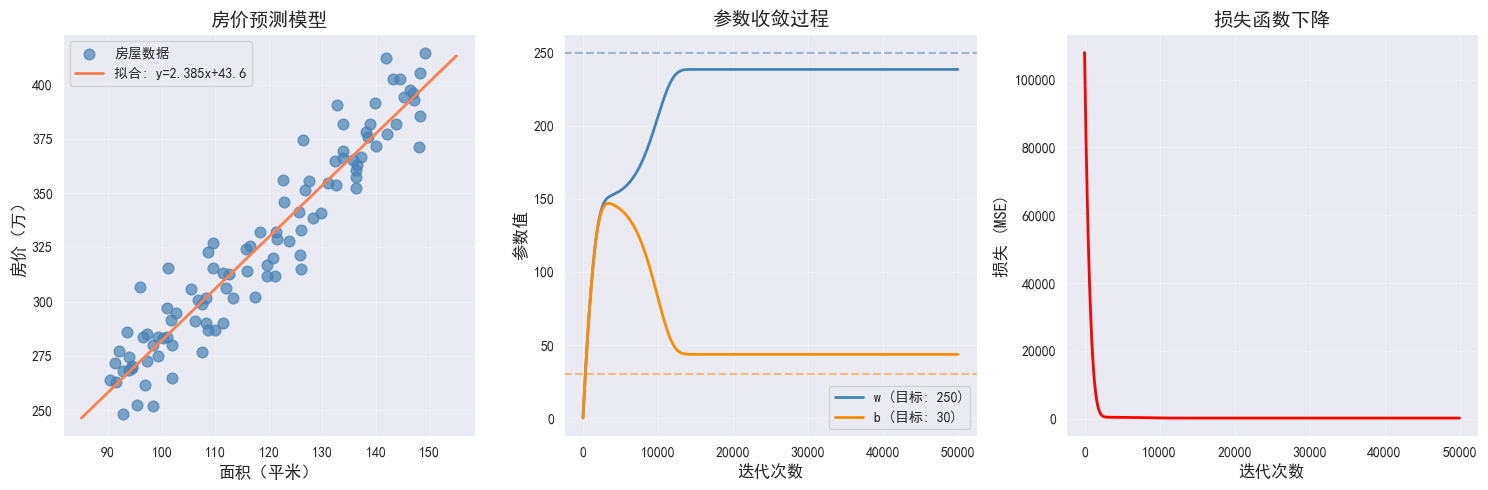

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# ================= 字体与画风设置 =================
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ================= 1. 生成数据 =================
np.random.seed(42)
n_samples = 100
areas_m2 = np.random.uniform(90, 150, n_samples) # 面积（平米）
areas = areas_m2 / 100                           # 转换为百平米（用于训练）
prices = 250 * areas + 30 + np.random.randn(n_samples) * 15 # 房价（万）

# ================= 2. Adam 优化器实现 =================
def adam_optimizer(X, y, lr=0.1, epochs=50000, beta1=0.9, beta2=0.999, epsilon=1e-8):
    w, b = 0.0, 0.0
    n = len(X)

    # Adam 特有的状态变量初始化
    m_w, v_w = 0.0, 0.0  # w 的一阶矩和二阶矩
    m_b, v_b = 0.0, 0.0  # b 的一阶矩和二阶矩

    # 初始化历史记录
    history = {'w': [w], 'b': [b], 'loss': [np.mean((w*X + b - y) ** 2)]}

    for epoch in range(epochs):
        t = epoch + 1  # 时间步，用于偏差校正

        # 计算预测值
        y_pred = w * X + b
        current_loss = np.mean((y_pred - y) ** 2)

        # 计算梯度
        dw = (2/n) * np.sum((y_pred - y) * X)
        db = (2/n) * np.sum(y_pred - y)

        # 更新一阶矩估计
        m_w = beta1 * m_w + (1 - beta1) * dw
        m_b = beta1 * m_b + (1 - beta1) * db

        # 更新二阶矩估计
        v_w = beta2 * v_w + (1 - beta2) * (dw ** 2)
        v_b = beta2 * v_b + (1 - beta2) * (db ** 2)

        # 偏差校正
        m_w_hat = m_w / (1 - beta1 ** t)
        m_b_hat = m_b / (1 - beta1 ** t)
        v_w_hat = v_w / (1 - beta2 ** t)
        v_b_hat = v_b / (1 - beta2 ** t)

        # 更新参数
        w = w - lr * m_w_hat / (np.sqrt(v_w_hat) + epsilon)
        b = b - lr * m_b_hat / (np.sqrt(v_b_hat) + epsilon)

        # 记录参数和损失
        history['w'].append(w)
        history['b'].append(b)
        history['loss'].append(current_loss)

        # 每隔 1% 打印进度
        print_step = max(1, int(epochs / 100))
        if epoch % print_step == 0:
            print(f"迭代 {epoch:5d}: w={w:.4f}, b={b:.4f}, loss={current_loss:.4f}")

    return history

# 运行 Adam 优化器训练
history = adam_optimizer(areas, prices, lr=0.1, epochs=50000)
print(f"\n最终结果: 房价 = {history['w'][-1]/100:.3f} x 面积(平米) + {history['b'][-1]:.2f}")

# ================= 3. 可视化绘制（与截图效果一致） =================
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# ------------ 图1：房屋数据散点与拟合曲线 ------------
axes[0].scatter(areas_m2, prices, c='steelblue', s=60, alpha=0.7, label='房屋数据')

# 绘制拟合曲线（注意：w的训练是基于百平米，x_line是平米，所以斜率需要除以100）
x_line = np.linspace(85, 155, 100)
y_line = (history['w'][-1] / 100) * x_line + history['b'][-1]
axes[0].plot(x_line, y_line, 'coral', lw=2, 
             label=f'拟合: y={history["w"][-1]/100:.3f}x+{history["b"][-1]:.1f}')

axes[0].set_xlabel('面积（平米）', fontsize=12)
axes[0].set_ylabel('房价（万）', fontsize=12)
axes[0].set_title('房价预测模型', fontsize=14)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# ------------ 图2：参数收敛过程 ------------
# 绘制 w 和 b 的目标参考线（虚线）
axes[1].axhline(250, color='steelblue', ls='--', alpha=0.5)
axes[1].axhline(30, color='darkorange', ls='--', alpha=0.5)

# 绘制 w 和 b 的收敛轨迹
axes[1].plot(history['w'], 'steelblue', lw=2, label='w (目标: 250)')
axes[1].plot(history['b'], 'darkorange', lw=2, label='b (目标: 30)')

axes[1].set_xlabel('迭代次数', fontsize=12)
axes[1].set_ylabel('参数值', fontsize=12)
axes[1].set_title('参数收敛过程', fontsize=14)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

# ------------ 图3：损失函数下降 ------------
axes[2].plot(history['loss'], 'red', lw=2)

axes[2].set_xlabel('迭代次数', fontsize=12)
axes[2].set_ylabel('损失 (MSE)', fontsize=12)
axes[2].set_title('损失函数下降', fontsize=14)
axes[2].grid(True, alpha=0.3)

# 调整布局并显示
plt.tight_layout()
plt.show()